# Statistics for ML in Finance - Part II

This notebook is a beginner-friendly continuation of the earlier statistics notebook. It focuses on practical use cases that happen often in finance and ML work:

1. Finding the closest assets and building a portfolio based on volatility, volatility ratio, and correlation
2. Checking whether a stock is similar to another stock using correlation, beta, and residuals
3. Building a diversified portfolio with clustering
4. Selecting features so they are meaningful and not just noisy

The goal is not to memorize formulas. The goal is to learn how to think like a beginner analyst: ask the question, measure the relationship, validate the model, and check whether the relationship is drifting over time.

> Important: all examples below are synthetic data for learning. They are not real trading advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

rng = np.random.default_rng(42)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
np.set_printoptions(precision=4, suppress=True)
print('Notebook setup complete.')

Notebook setup complete.


## 1) Finding the closest assets and portfolio construction

A beginner question is: "Which assets behave most similarly to each other?"

We often compare assets using:
- correlation: do they move together?
- volatility: how much do they move?
- volatility ratio: does one asset move more or less than the other relative to a benchmark?

If two assets have high correlation but very different volatility, they may not be good substitutes in a portfolio. A portfolio manager usually wants a mix of assets that move together enough to explain the same risk, but not so much that diversification disappears.

### Beginner mental model

Think of it like choosing teammates for a team project. You want people who are productive and compatible, but you do not want everyone to be identical. In finance, similarity is useful, but too much similarity can create concentration risk.

Pairwise correlation matrix:
         Asset_A  Asset_B  Asset_C  Asset_D  Asset_E  Asset_F  Market
Asset_A    1.000    0.519    0.344    0.111    0.243    0.616   0.766
Asset_B    0.519    1.000    0.287    0.056    0.225    0.509   0.699
Asset_C    0.344    0.287    1.000    0.043    0.135    0.266   0.397
Asset_D    0.111    0.056    0.043    1.000    0.002    0.093   0.119
Asset_E    0.243    0.225    0.135    0.002    1.000    0.269   0.313
Asset_F    0.616    0.509    0.266    0.093    0.269    1.000   0.783
Market     0.766    0.699    0.397    0.119    0.313    0.783   1.000

Volatility ratio to market:
Asset_A    1.101
Asset_B    1.238
Asset_C    0.852
Asset_D    1.603
Asset_E    2.036
Asset_F    0.809
Market     1.000
dtype: float64


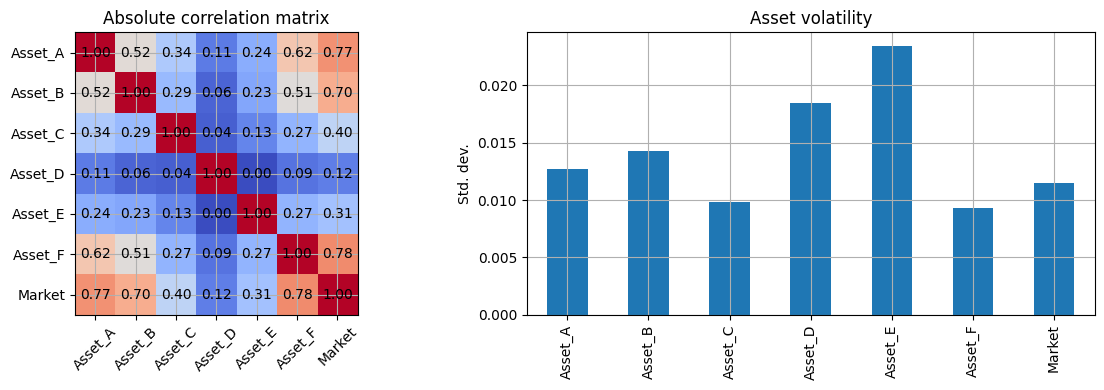

In [2]:
n = 500
market = rng.normal(0, 0.012, n)
asset_a = 0.85 * market + rng.normal(0, 0.008, n)
asset_b = 0.82 * market + rng.normal(0, 0.010, n)
asset_c = -0.30 * market + rng.normal(0, 0.009, n)
asset_d = 0.10 * market + rng.normal(0, 0.018, n)
asset_e = 0.70 * market + rng.normal(0, 0.022, n)
asset_f = 0.65 * market + rng.normal(0, 0.006, n)

returns = pd.DataFrame({
    'Asset_A': asset_a,
    'Asset_B': asset_b,
    'Asset_C': asset_c,
    'Asset_D': asset_d,
    'Asset_E': asset_e,
    'Asset_F': asset_f,
    'Market': market
})

corr_matrix = returns.corr().abs()
vol = returns.std(ddof=1)
vol_ratio = vol / vol['Market']

print('Pairwise correlation matrix:')
print(corr_matrix.round(3))
print('\nVolatility ratio to market:')
print(vol_ratio.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(corr_matrix, cmap='coolwarm', vmin=0, vmax=1)
axes[0].set_title('Absolute correlation matrix')
axes[0].set_xticks(range(len(corr_matrix.columns)))
axes[0].set_xticklabels(corr_matrix.columns, rotation=45)
axes[0].set_yticks(range(len(corr_matrix.columns)))
axes[0].set_yticklabels(corr_matrix.columns)
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        axes[0].text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center', color='black')

vol.plot(kind='bar', ax=axes[1])
axes[1].set_title('Asset volatility')
axes[1].set_ylabel('Std. dev.')
plt.tight_layout()
plt.show()

### What does this tell us?

We can see that some assets are very close to each other on the market factor. But closeness is not always the same as being a good portfolio construction choice.

In a real portfolio case:
- we may choose the asset that has the strongest correlation with a benchmark,
- we may prefer lower volatility if we are worried about risk,
- we may avoid assets that are too similar because that creates concentration risk.

### Validating whether the relationship is still valid

A model can look good in one period and fail later. This is called model drift. In practice, you should check whether the relationship is stable over time.

For a simple asset comparison, we can compute rolling values and look for structural breaks.

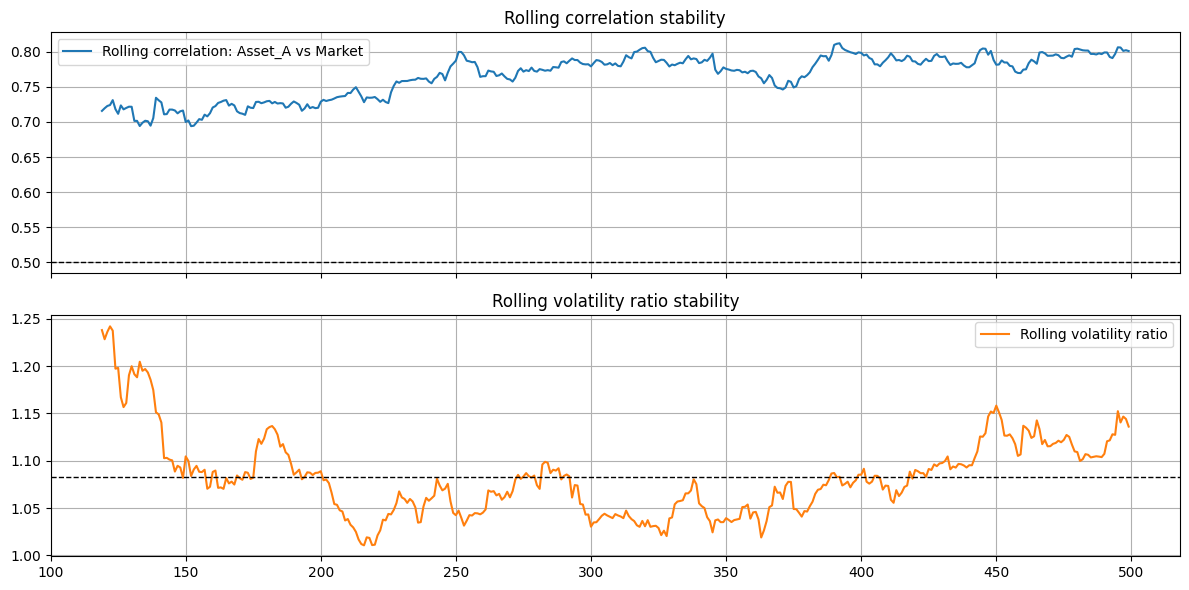

Recent correlation estimate: 0.8010331551557756
Recent volatility ratio estimate: 1.1360797180079438
Interpretation: if rolling correlation or vol ratio changes sharply, the relationship may not be stable enough to hold in production.


In [3]:
# Rolling correlation and volatility ratio to check drift
window = 120
rolling_corr = returns['Asset_A'].rolling(window).corr(returns['Market'])
rolling_vol = returns['Asset_A'].rolling(window).std() / returns['Market'].rolling(window).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(rolling_corr, label='Rolling correlation: Asset_A vs Market')
axes[0].axhline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set_title('Rolling correlation stability')
axes[0].legend()
axes[1].plot(rolling_vol, color='tab:orange', label='Rolling volatility ratio')
axes[1].axhline(rolling_vol.mean(), color='black', linestyle='--', linewidth=1)
axes[1].set_title('Rolling volatility ratio stability')
axes[1].legend()
plt.tight_layout()
plt.show()

print('Recent correlation estimate:', rolling_corr.dropna().iloc[-1])
print('Recent volatility ratio estimate:', rolling_vol.dropna().iloc[-1])
print('Interpretation: if rolling correlation or vol ratio changes sharply, the relationship may not be stable enough to hold in production.')

## 2) Investigating whether a stock is similar to another using correlation, beta, and residuals

This is a very common financial analysis question. For example, you may ask: "Is this stock similar to the index or to another stock?"

The simplest answer is to check:
- correlation: how strongly do they move together?
- beta: how sensitive is the stock to the market factor?
- residuals: after controlling for the market factor, is there still unexplained behavior?

### Why residuals matter

Two stocks can have a high correlation because both rise with the market. But that does not mean they are truly similar. The real question is whether they still behave similarly after removing the common market movement.

This is where beta and residual analysis becomes useful.

Stock_1: correlation=0.528, beta=0.865, residual_std=0.0162, R²=0.279
Stock_2: correlation=0.523, beta=0.688, residual_std=0.0130, R²=0.274
Stock_3: correlation=0.502, beta=1.006, residual_std=0.0202, R²=0.252


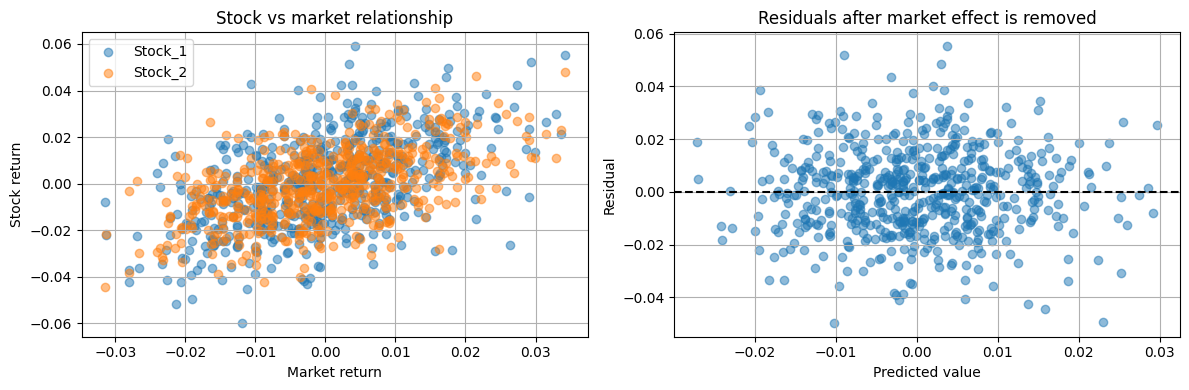

In [4]:
# Synthetic stock comparison
n = 600
market = rng.normal(0, 0.012, n)
stock_1 = 0.9 * market + rng.normal(0, 0.016, n)
stock_2 = 0.75 * market + rng.normal(0, 0.013, n)
stock_3 = 0.95 * market + rng.normal(0, 0.020, n)

df = pd.DataFrame({
    'Market': market,
    'Stock_1': stock_1,
    'Stock_2': stock_2,
    'Stock_3': stock_3
})

for stock in ['Stock_1', 'Stock_2', 'Stock_3']:
    X = df['Market'].values.reshape(-1, 1)
    y = df[stock].values
    model = LinearRegression().fit(X, y)
    pred = model.predict(X)
    residual = y - pred
    corr = df['Market'].corr(df[stock])
    beta = model.coef_[0]
    print(f'{stock}: correlation={corr:.3f}, beta={beta:.3f}, residual_std={residual.std(ddof=1):.4f}, R²={r2_score(y, pred):.3f}')

# Visual diagnostic
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df['Market'], df['Stock_1'], alpha=0.5, label='Stock_1')
axes[0].scatter(df['Market'], df['Stock_2'], alpha=0.5, label='Stock_2')
axes[0].set_title('Stock vs market relationship')
axes[0].set_xlabel('Market return')
axes[0].set_ylabel('Stock return')
axes[0].legend()

model = LinearRegression().fit(df['Market'].values.reshape(-1, 1), df['Stock_1'].values)
pred = model.predict(df['Market'].values.reshape(-1, 1))
resid = df['Stock_1'].values - pred
axes[1].scatter(pred, resid, alpha=0.5)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title('Residuals after market effect is removed')
axes[1].set_xlabel('Predicted value')
axes[1].set_ylabel('Residual')
plt.tight_layout()
plt.show()

### Drift validation

Even if correlation looks good today, it may not stay good tomorrow. We can test stability using rolling beta and rolling correlation.

A beginner-friendly drift check should also ask a second question: has the distribution changed? If the early-period and late-period returns look very different, then the relationship may not be stable even if the average is still similar.

In practice, we often combine three checks:

- distribution check: do the return distributions shift over time?
- stationarity test: is the series stable enough to behave like a consistent process?
- t-test: are the early and late means meaningfully different?

If the beta or residual pattern changes a lot over time, then the stock is not truly stable enough to treat as equivalent to another stock.

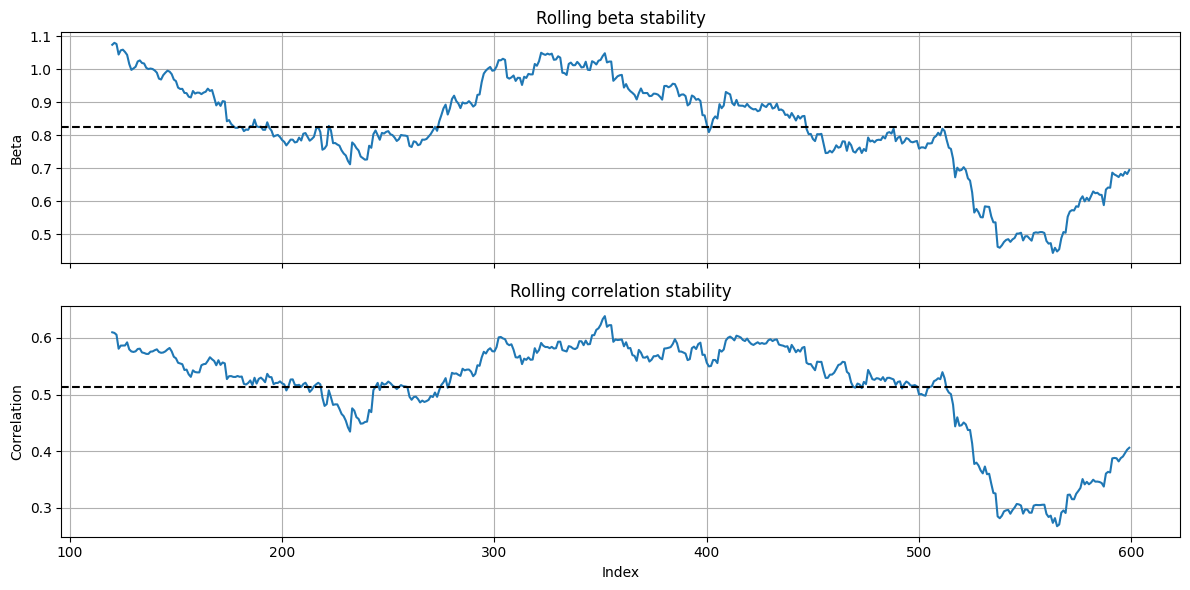

Average rolling beta: 0.8250277346725571
Latest rolling beta: 0.6942549487566287
Latest rolling correlation: 0.40614976558347915


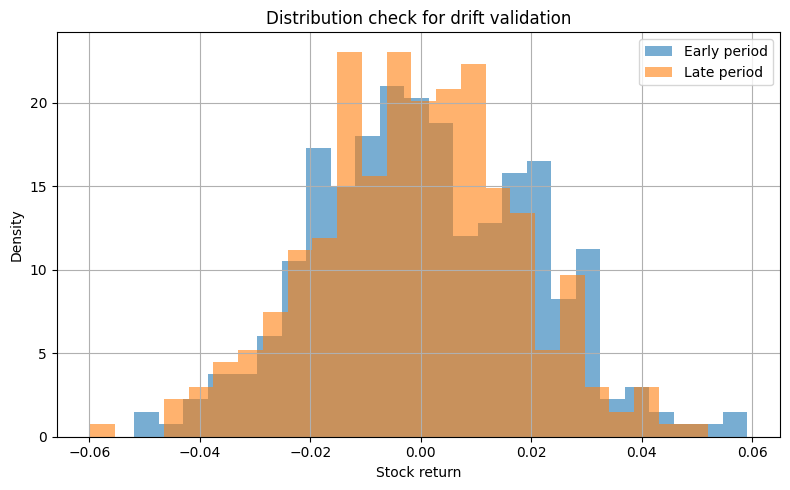

ADF statistic: -6.7162
ADF p-value: 0.0000
Interpretation: a small p-value suggests the series is more stationary; a large p-value suggests non-stationarity.
Two-sample t-test statistic: 1.2198
Two-sample t-test p-value: 0.2230
Interpretation: if p-value < 0.05, the early and late return means differ meaningfully enough to suggest drift.


In [19]:
# Rolling beta and correlation to detect drift
window = 120
rolling_beta = []
rolling_corr = []

for i in range(window, len(df)):
    X = df['Market'].iloc[i-window:i].values.reshape(-1, 1)
    y = df['Stock_1'].iloc[i-window:i].values
    model = LinearRegression().fit(X, y)
    rolling_beta.append((i, model.coef_[0]))
    rolling_corr.append((i, df['Market'].iloc[i-window:i].corr(df['Stock_1'].iloc[i-window:i])))

beta_df = pd.DataFrame(rolling_beta, columns=['index', 'beta'])
corr_df = pd.DataFrame(rolling_corr, columns=['index', 'corr'])

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(beta_df['index'], beta_df['beta'])
axes[0].axhline(beta_df['beta'].mean(), color='black', linestyle='--')
axes[0].set_title('Rolling beta stability')
axes[0].set_ylabel('Beta')
axes[1].plot(corr_df['index'], corr_df['corr'])
axes[1].axhline(corr_df['corr'].mean(), color='black', linestyle='--')
axes[1].set_title('Rolling correlation stability')
axes[1].set_ylabel('Correlation')
axes[1].set_xlabel('Index')
plt.tight_layout()
plt.show()

print('Average rolling beta:', beta_df['beta'].mean())
print('Latest rolling beta:', beta_df['beta'].iloc[-1])
print('Latest rolling correlation:', corr_df['corr'].iloc[-1])

# Distribution check: compare the first half and second half of the series
midpoint = len(df) // 2
early = df['Stock_1'].iloc[:midpoint].values
late = df['Stock_1'].iloc[midpoint:].values

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(early, bins=25, alpha=0.6, label='Early period', density=True)
ax.hist(late, bins=25, alpha=0.6, label='Late period', density=True)
ax.set_title('Distribution check for drift validation')
ax.set_xlabel('Stock return')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.show()

# Stationarity test: ADF (Augmented Dickey-Fuller)
from statsmodels.tsa.stattools import adfuller
adf_stat, adf_pvalue, *_ = adfuller(df['Stock_1'].values)
print(f'ADF statistic: {adf_stat:.4f}')
print(f'ADF p-value: {adf_pvalue:.4f}')
print('Interpretation: a small p-value suggests the series is more stationary; a large p-value suggests non-stationarity.')

# Two-sample t-test: are early and late return means significantly different?
t_stat, p_value = stats.ttest_ind(early, late, equal_var=False)
print(f'Two-sample t-test statistic: {t_stat:.4f}')
print(f'Two-sample t-test p-value: {p_value:.4f}')
print('Interpretation: if p-value < 0.05, the early and late return means differ meaningfully enough to suggest drift.')

## 3) Constructing a diversified portfolio using clustering

Clustering is a simple way to group assets that behave similarly. Instead of looking at each asset one by one, we can group them into clusters based on their patterns and then choose one or a few representatives from each cluster.

This is useful because a diversified portfolio should not be made of only highly similar assets. You want balance across risk groups.

### Beginner mental model

Think of this as organizing a basket of fruits by type. You may have several apples, several pears, and several bananas. If you build a portfolio from only apples, you are concentrated. If you include multiple groups, you are more diversified.

  Asset  Cluster
6    C1        0
0    A1        1
2    A3        1
1    A2        1
3    B1        1
4    B2        1
5    B3        1
7    C2        2

Selected assets for diversified portfolio: ['C1', 'A1', 'C2']
Portfolio volatility: 7.8756


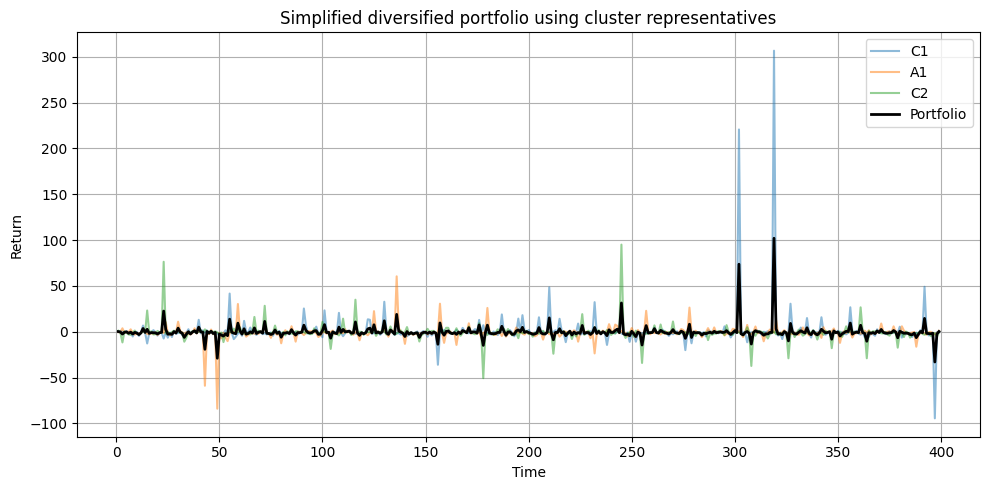

In [15]:
# Build a synthetic asset universe with clustered behavior
n = 400
market = rng.normal(0, 0.012, n)
f1 = rng.normal(0, 0.010, n)
f2 = rng.normal(0, 0.009, n)

assets = pd.DataFrame({
    'A1': 0.9 * market + 0.2 * f1 + rng.normal(0, 0.008, n),
    'A2': 0.88 * market + 0.18 * f1 + rng.normal(0, 0.010, n),
    'A3': 0.80 * market + 0.25 * f1 + rng.normal(0, 0.009, n),
    'B1': -0.70 * market + 0.6 * f2 + rng.normal(0, 0.012, n),
    'B2': -0.75 * market + 0.55 * f2 + rng.normal(0, 0.011, n),
    'B3': -0.68 * market + 0.50 * f2 + rng.normal(0, 0.010, n),
    'C1': 0.3 * f1 + 0.7 * f2 + rng.normal(0, 0.015, n),
    'C2': 0.25 * f1 + 0.8 * f2 + rng.normal(0, 0.013, n)
})

returns = assets.pct_change().dropna()

# Cluster assets by their return patterns across time
X = StandardScaler().fit_transform(returns.T)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X)

cluster_df = pd.DataFrame({'Asset': returns.columns, 'Cluster': cluster_labels})
print(cluster_df.sort_values('Cluster'))

# Build a simple diversified portfolio using one asset per cluster
selected = []
for cluster_id in sorted(cluster_df['Cluster'].unique()):
    members = cluster_df[cluster_df['Cluster'] == cluster_id]['Asset'].tolist()
    sel = members[0]
    selected.append(sel)

portfolio_assets = returns[selected]
weights = np.array([1 / len(selected)] * len(selected))
portfolio_returns = pd.Series(portfolio_assets.dot(weights), index=portfolio_assets.index)
portfolio_vol = portfolio_returns.std(ddof=1)

print(f'\nSelected assets for diversified portfolio: {selected}')
print(f'Portfolio volatility: {portfolio_vol:.4f}')

fig, ax = plt.subplots(figsize=(10, 5))
for asset in portfolio_assets.columns:
    ax.plot(portfolio_assets[asset], alpha=0.5, label=asset)
ax.plot(portfolio_returns, linewidth=2, color='black', label='Portfolio')
ax.set_title('Simplified diversified portfolio using cluster representatives')
ax.set_xlabel('Time')
ax.set_ylabel('Return')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

### How to validate cluster-based portfolio design

Clustering is helpful, but it does not mean your portfolio is automatically good. You still need to validate:
- Are the clusters stable over time?
- Does the chosen set really lower portfolio volatility?
- Are some assets still too similar after clustering?
- Has the portfolio drifted because the market regime changed?

A practical validation method is to compare rolling volatility and rolling correlation of the portfolio to the market over time.

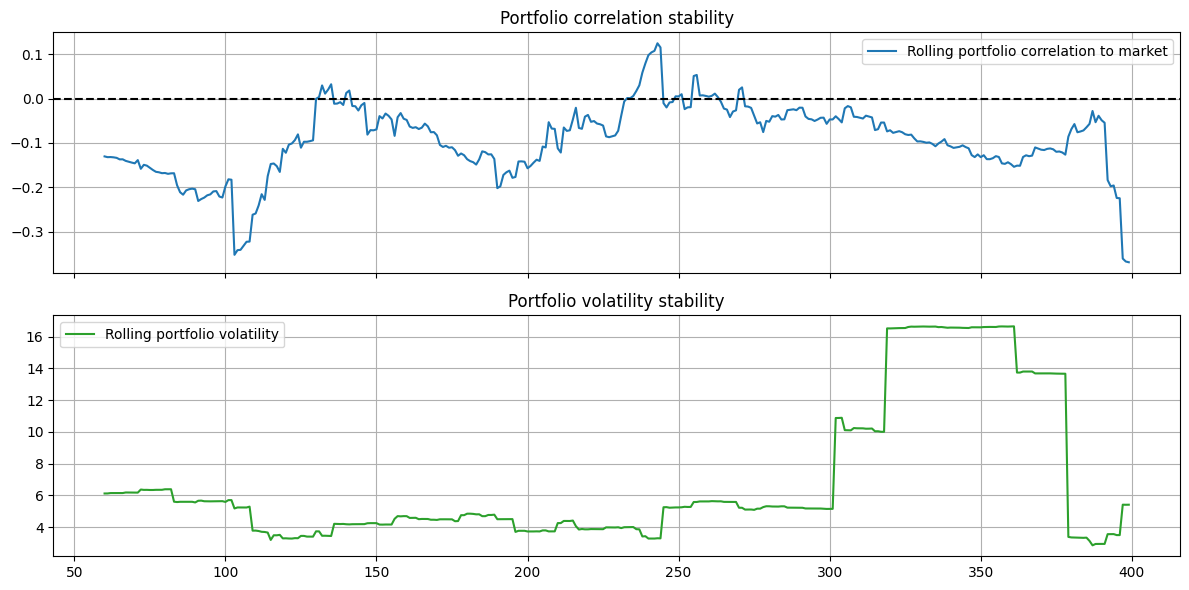

Mean rolling portfolio correlation: -0.09341345072196269
Mean rolling portfolio vol: 6.876681770297808


In [16]:
# Rolling validation of portfolio stability
market_series = pd.Series(market[-len(portfolio_returns):], index=portfolio_returns.index)
rolling_port_corr = portfolio_returns.rolling(60).corr(market_series)
rolling_port_vol = portfolio_returns.rolling(60).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(rolling_port_corr, label='Rolling portfolio correlation to market')
axes[0].axhline(0.0, color='black', linestyle='--')
axes[0].legend()
axes[0].set_title('Portfolio correlation stability')
axes[1].plot(rolling_port_vol, color='tab:green', label='Rolling portfolio volatility')
axes[1].set_title('Portfolio volatility stability')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Mean rolling portfolio correlation:', rolling_port_corr.dropna().mean())
print('Mean rolling portfolio vol:', rolling_port_vol.dropna().mean())

## 4) Feature selection: making sure features are meaningful and not just noisy

Feature selection is the process of choosing variables that truly help explain the target. In finance and ML, this is extremely important. A model can become worse if you add features that are noisy, redundant, or not related to the target.

### Beginner idea

A feature is useful if it is:
- connected to the target,
- stable over time,
- not redundant with other features that add almost no new information,
- understandable from a business perspective.

If a feature has a weak relationship to the target and is highly similar to another feature, it may not be worth keeping.

In [18]:
# Synthetic feature data
n = 800
market_factor = rng.normal(0, 1, n)
feature_1 = 0.8 * market_factor + rng.normal(0, 0.7, n)
feature_2 = 0.75 * market_factor + rng.normal(0, 0.8, n)
feature_3 = 0.05 * market_factor + rng.normal(0, 1.2, n)
feature_4 = rng.normal(0, 1.2, n)
feature_5 = 0.82 * market_factor + rng.normal(0, 0.8, n)
target = 0.6 * feature_1 + 0.25 * feature_2 + 0.1 * feature_3 + rng.normal(0, 0.5, n)

features = pd.DataFrame({
    'feature_1': feature_1,
    'feature_2': feature_2,
    'feature_3': feature_3,
    'feature_4': feature_4,
    'feature_5': feature_5,
    'target': target
})

corr = features.corr().abs()
relation_to_target = corr['target'].drop('target').sort_values(ascending=False)
print('Feature correlation to target:')
print(relation_to_target)

# Show which features are highly redundant
redundancy = corr.drop('target', axis=1).where(~np.eye(len(corr)), np.nan)
print('\nFeature redundancy (absolute correlation, excluding self):')
print(redundancy.round(2))

# A simple feature selection rule: keep the strongest predictor from each highly similar cluster
feature_names = [c for c in features.columns if c != 'target']
cluster_input = corr.loc[feature_names, feature_names].values
distance = 1 - cluster_input
clusterer = AgglomerativeClustering(n_clusters=2, metric='precomputed', linkage='average')
clusters = clusterer.fit_predict(distance)
cluster_map = pd.DataFrame({'feature': feature_names, 'cluster': clusters})
print('\nCluster assignment for features:')
print(cluster_map)

# Visual show strong features vs weak features
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(relation_to_target.index, relation_to_target.values, color='steelblue')
ax.axhline(0.5, color='black', linestyle='--', linewidth=1)
ax.set_title('Absolute feature correlation with target')
ax.set_xlabel('Feature')
ax.set_ylabel('Absolute correlation')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Feature correlation to target:
feature_1    0.818468
feature_2    0.603880
feature_5    0.546976
feature_3    0.125072
feature_4    0.033295
Name: target, dtype: float64


TypeError: ufunc 'invert' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

### Why this matters

At a beginner level, feature selection is really about asking a simple question: "Does this variable help me make a better business decision, or is it just adding noise?"

A model can look impressive on paper while still being bad in practice if it uses features that are:
- weakly related to the target,
- redundant with other variables,
- unstable over time,
- hard to explain in plain business terms.

### Simple business example

Imagine you are building a model to predict whether a stock will underperform the market next month.

A feature like "company revenue growth" is probably useful because it matches a real business story.
A feature like "a random price change from yesterday" may look noisy and may not carry useful information.

Good features help answer real questions such as:
- What drives this return?
- What is associated with default risk?
- Is this factor informative after controlling for obvious market effects?

### Beginner rule

Keep a feature when it is:
- related to the target,
- stable and not too noisy,
- not almost a copy of another feature,
- understandable to a portfolio manager or risk analyst.

Drop it when it is:
- weakly connected to the target,
- highly redundant with a stronger feature,
- unstable across time,
- hard to explain with a business story.

This is the core idea: feature selection is not about adding more variables. It is about keeping the variables that actually help you understand and act on the problem.

VaR and stress VaR (sVaR): how much can we lose in a bad day?\n\nValue at Risk, or VaR, answers a very practical question: \"If markets behave normally, how bad could my portfolio get over a fixed time horizon?\"\n\nFor a beginner, think of VaR as a risk alarm threshold. It tells you the level of loss that is rare but still possible.\n\n### Beginner idea\n\nSuppose a portfolio has a 95% daily VaR of 2%. That means:\n- in the usual market environment, there is a 5% chance of losing more than 2% in one day;\n- the portfolio is expected to be fine most of the time, but there is a tail-risk event that can be painful;\n- this is why risk managers care about the tails of the distribution.\n\nVaR usually has two parts:\n- a confidence level, such as 95% or 99%;\n- a time horizon, such as 1 day or 10 days.\n\n### What is stress VaR?\n\nStress VaR, or sVaR, is a different question. It asks: \"What happens if the market enters a stressed period instead of a normal one?\"\n\nThis is important because standard VaR can underestimate danger during panic selling, liquidity shocks, or sudden macro news. A portfolio may look safe under normal conditions but still break under stress.\n\n### Real-world use cases\n\nVaR and sVaR are used when a desk, fund, or bank needs to answer questions like:\n- How much loss can we tolerate in a normal trading day?\n- Are we inside our risk limits?\n- What if the market falls sharply in a short time?\n- Do we need extra capital or tighter exposure controls?\n\nThis makes VaR and sVaR useful for risk monitoring, capital allocation, and portfolio oversight.\n

95% daily VaR: 0.0119 (1.19% loss threshold)
99% daily VaR: 0.0167 (1.67% loss threshold)
95% stress VaR: 0.0596 (5.96% loss threshold)
99% stress VaR: 0.0719 (7.19% loss threshold)


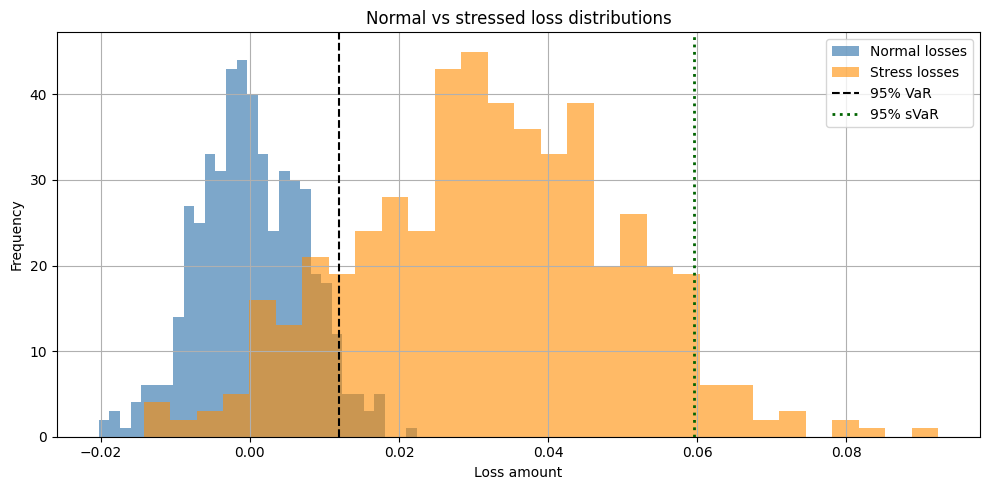


Interpretation:
- VaR tells us the loss threshold under normal conditions.
- Stress VaR tells us what happens when markets are under severe pressure.
- If stress VaR is much larger than VaR, the portfolio may be fragile even when normal daily risk looks acceptable.


In [10]:
# Simulate a simple portfolio with normal and stressed market conditions
rng = np.random.default_rng(42)

n_days = 500
normal_market = rng.normal(0, 0.01, n_days)
sector_move = rng.normal(0, 0.012, n_days)
idiosyncratic = rng.normal(0, 0.018, n_days)

portfolio_returns = 0.6 * normal_market + 0.3 * sector_move + 0.1 * idiosyncratic

# Turn returns into losses for VaR calculations
portfolio_losses = -portfolio_returns

# VaR at different confidence levels
var_95 = np.quantile(portfolio_losses, 0.95)
var_99 = np.quantile(portfolio_losses, 0.99)

print(f'95% daily VaR: {var_95:.4f} ({var_95 * 100:.2f}% loss threshold)')
print(f'99% daily VaR: {var_99:.4f} ({var_99 * 100:.2f}% loss threshold)')

# Stress scenario: a sharp market sell-off plus extra volatility
stress_market = -0.04 + rng.normal(0, 0.025, n_days)
stress_sector = -0.02 + rng.normal(0, 0.03, n_days)
stress_idio = rng.normal(0, 0.025, n_days)

stress_returns = 0.6 * stress_market + 0.3 * stress_sector + 0.1 * stress_idio
stress_losses = -stress_returns

svar_95 = np.quantile(stress_losses, 0.95)
svar_99 = np.quantile(stress_losses, 0.99)

print(f'95% stress VaR: {svar_95:.4f} ({svar_95 * 100:.2f}% loss threshold)')
print(f'99% stress VaR: {svar_99:.4f} ({svar_99 * 100:.2f}% loss threshold)')

# Compare the two distributions visually
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(portfolio_losses, bins=30, alpha=0.7, color='steelblue', label='Normal losses')
ax.hist(stress_losses, bins=30, alpha=0.6, color='darkorange', label='Stress losses')
ax.axvline(var_95, color='black', linestyle='--', linewidth=1.5, label='95% VaR')
ax.axvline(svar_95, color='darkgreen', linestyle=':', linewidth=2, label='95% sVaR')
ax.set_title('Normal vs stressed loss distributions')
ax.set_xlabel('Loss amount')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.show()

# Simple interpretation for decision-making
print('\nInterpretation:')
print('- VaR tells us the loss threshold under normal conditions.')
print('- Stress VaR tells us what happens when markets are under severe pressure.')
print('- If stress VaR is much larger than VaR, the portfolio may be fragile even when normal daily risk looks acceptable.')


95% VaR threshold: 0.0570 (5.70%)
Breaches without action: 13
Breaches with reduced exposure: 1


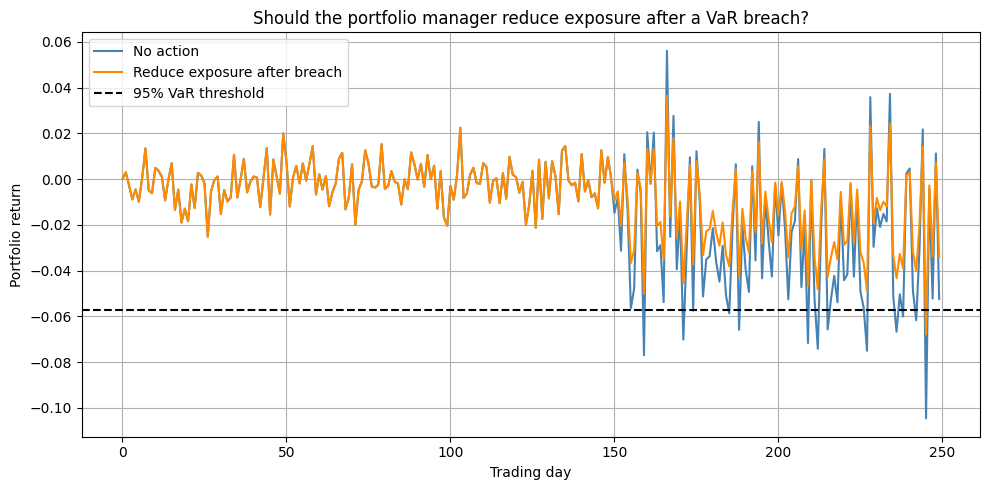


Interpretation:
- A VaR breach by itself is a warning, not necessarily a portfolio disaster.
- Repeated breaches suggest the market regime has changed or the exposure is too large.
- Reducing exposure can protect the portfolio during a stress period, but the action should be disciplined and based on risk policy.


In [11]:
# Use case: portfolio manager decision after a VaR breach
rng = np.random.default_rng(7)

n_days = 250
normal_returns = rng.normal(0, 0.01, n_days)
stress_returns = rng.normal(-0.02, 0.03, n_days)

# Simulate a normal regime followed by a market stress period
portfolio_no_action = np.concatenate([
    normal_returns[:150],
    stress_returns[150:],
])

# If a breach happens, the manager cuts exposure by 35%
portfolio_with_reduction = np.concatenate([
    normal_returns[:150],
    0.65 * stress_returns[150:],
])

loss_no_action = -portfolio_no_action
loss_with_reduction = -portfolio_with_reduction

var_95 = np.quantile(loss_no_action, 0.95)

breaches_no_action = np.sum(loss_no_action > var_95)
breaches_with_reduction = np.sum(loss_with_reduction > var_95)

print(f'95% VaR threshold: {var_95:.4f} ({var_95 * 100:.2f}%)')
print(f'Breaches without action: {breaches_no_action}')
print(f'Breaches with reduced exposure: {breaches_with_reduction}')

fig, ax = plt.subplots(figsize=(10, 5))
days = np.arange(len(portfolio_no_action))
ax.plot(days, portfolio_no_action, label='No action', color='steelblue')
ax.plot(days, portfolio_with_reduction, label='Reduce exposure after breach', color='darkorange')
ax.axhline(-var_95, color='black', linestyle='--', linewidth=1.5, label='95% VaR threshold')
ax.set_title('Should the portfolio manager reduce exposure after a VaR breach?')
ax.set_xlabel('Trading day')
ax.set_ylabel('Portfolio return')
ax.legend()
plt.tight_layout()
plt.show()

print('\nInterpretation:')
print('- A VaR breach by itself is a warning, not necessarily a portfolio disaster.')
print('- Repeated breaches suggest the market regime has changed or the exposure is too large.')
print('- Reducing exposure can protect the portfolio during a stress period, but the action should be disciplined and based on risk policy.')


### Use case 2: Should we reduce exposure after a VaR breach?\n\nA VaR breach is a signal, not automatically a disaster. It means the portfolio lost more than the amount we expected under normal conditions.\n\nFor a portfolio manager, the key question is not simply \"Did we breach VaR?\" but rather \"Is this a one-off event or a sign that the portfolio is too exposed to a changing market regime?\"\n\n### A simple decision rule\n\nA beginner-friendly rule is:\n- If the breach is isolated and market conditions quickly normalize, the manager may wait and investigate.\n- If the breach repeats several times in a short period, or if volatility is rising sharply, the manager should consider reducing exposure.\n- If the portfolio is highly concentrated or has hidden factor exposures, a breach is a warning that the risk model may be incomplete.\n\nThis is exactly why portfolio managers do not treat VaR breaches as just a technical detail. They are operational signals.\n\n### Why this matters in practice\n\nA risk limit is useful only if it helps you make a decision. Without action, a consistent VaR breach can quietly turn a manageable portfolio into a fragile one.\n\nIn practice, a manager may reduce exposure when:\n- the portfolio repeatedly exceeds its 95% or 99% VaR threshold,\n- stress VaR is much worse than normal VaR,\n- the portfolio is concentrated in a sector or factor that is now acting badly,\n- the market is entering a liquidity or volatility shock.\n\nThe goal is not panic. The goal is disciplined risk control.\n\n### Beginner interpretation\n\nThink of VaR as a warning light. A single warning light does not necessarily mean the engine is broken, but multiple warnings in a short time mean it is time to slow down.\n\nA good risk manager asks:\n- Is this a temporary fluctuation or a trend?\n- Is the risk model still valid?\n- Are we taking more risk than the portfolio can handle?\n\nThis is where risk management becomes a real business decision.\n\n## Final beginner checklist\n\nWhen working on asset similarity, portfolio design, validation, or feature selection, always ask yourself these questions:\n\n1. Is the relationship intuitive and explainable?\n2. Is the feature or asset similarity real, or is it mostly a market effect?\n3. Did I remove the common factor before comparing them?\n4. Are the results stable over time?\n5. Is there evidence of model drift?\n6. Are the features redundant or only noisy copies of each other?\n7. Is the final portfolio diversified enough to survive stress periods?\n\nIf the answer is unclear, then the model may not yet be trustworthy.\n\nThis is the beginner mindset: start with the business question, simplify the problem, validate carefully, and only then build the model.